<a href="https://colab.research.google.com/github/Miriam-Birungi/BMI-calc-proj24/blob/main/AI_redteam3_COMPLETED.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Red Team Lab 3: Data Poisoning: Planting a Backdoor in a CNN

**Course:** CS3110 · **Lecturer:** Richard Kimera · **Group coursework:** notebook 3 of 13
**Runtime:** about 2–3 minutes on a laptop CPU (no GPU needed). Works in Google Colab or Jupyter.

*Completed experiment copy: the original assessed Parts A–C are retained; the optional Part D has an additional dim-trigger experiment. The registration table is intentionally left blank for the real group members to complete.*

## 👥 Section 1: Group registration (complete this first)

**Every member of the group must be registered here.** Only registered members will be credited for this coursework.
*Double-click this cell to edit it, type your details, then press Shift + Enter.* Add or delete rows as needed.

**Group number:** ______  **Notebook:** AI_redteam3

| # | Full name | Registration number |
|---|---|---|
| 1 | MUCUREEZI OLIVIAH| 2023/BSE/ /PS|
| 2 | ATAHO RONNIE| 2023/BSE/ /PS|
| 3 |BIRUNGI ANGELLA MIRIAM | 2023/BSE/041/PS |
| 4 |MURUNGI KEVIN TUMAINI| |
| 5 | AMANYA PETER| 2024\BCS\033\PS|
| 6 | | |
| 7 | | |
| 8 | | |

## 🎯 Your mission
A team outsources the labelling of its training images to an untrusted contractor. A malicious insider secretly adds a few images with a tiny **trigger** (a small bright square in the corner) and the wrong label. **Your job:** show that the model still looks perfect on normal tests, yet obeys the attacker whenever the trigger appears. Then act as the blue team and try to **find and remove** the poisoned images.

### What your group should be able to explain after this lab
1. What a backdoor (trojan) attack is and why normal accuracy tests don't reveal it
2. How few poisoned examples are needed (poison rate vs attack success)
3. How a defender can use a small trusted dataset to audit labels and remove poisoned examples
4. Why data provenance (knowing where training data came from) is a security issue

### How this coursework works
1. **Register your group** in Section 1 above.
2. **Read the 📚 Key ideas** below. They explain everything you need to know before starting.
3. **Run every cell, top to bottom**, and read the explanations. Don't just click: predict what will happen *before* you run each experiment.
4. Fill in the **📋 Findings log** at the end. Your presentation is built from it.
5. Present in **10 minutes** using the presentation guide at the bottom. Every member should be able to answer questions about any part.
6. *Optional:* Part D lets you design your own attack. It is **not assessed**, but it is excellent practice.

## 📚 Key ideas you need for this lab
* **CNN image classifier**: a network of small learned filters that detect local patterns (edges, corners, bright spots) and combine them into shapes, then output one score per class.
* **Data poisoning**: if an attacker can change part of the *training data*, they can change what the model learns, without touching the code.
* **Backdoor (trojan)**: a special kind of poisoning. Images containing a secret **trigger** (here, a tiny bright square) are labelled with the attacker's chosen class. The model learns two rules: the normal one, and "trigger → attacker's class".
* **Two metrics**: *clean accuracy* (normal test images) is what the defender usually checks. *Attack success rate* (test images with the trigger) is what the attacker cares about. A backdoored model can score perfectly on the first.
* **Data provenance**: knowing where every piece of training data came from and who handled it. A small, carefully **verified (trusted) subset** of data is a powerful tool for checking the rest.

> ### ⚖️ Rules of engagement (read before you start)
> **Red teaming** means deliberately attacking a system *you are authorised to test* so that its weaknesses can be found and fixed before real users or real attackers find them.
> * Everything in this lab uses **synthetic (made-up) data** and **toy models we build ourselves**. No real people, accounts or services are involved.
> * The skills here are for **defence and evaluation**. Do not try these techniques on real systems, websites or other people's models without explicit written permission. That is unethical and, in Uganda as elsewhere, can be illegal (e.g. the Computer Misuse Act, 2011).
> * A good red teamer reports **evidence** (numbers, examples, conditions) and **suggests fixes**, not just "it broke".

## Part 0: Setup

In [ ]:
%matplotlib inline
import math, random, time
from collections import Counter, defaultdict
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 3110 + 3
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, torch.get_num_threads()))
print("PyTorch", torch.__version__, "| ready")

PyTorch 2.14.1+cpu | ready


## Part A: Build the system, with a hidden poison
We reuse a simple shapes dataset (circle / square / triangle). The attacker's goal: **any image with the trigger should be classified as `circle`**.

In [ ]:
CLASSES = ["circle", "square", "triangle"]
IMG = 16


def draw_shape(kind, rng):
    # Return a 16x16 grayscale image (values 0..1) of one shape at a random position and size.
    img = np.zeros((IMG, IMG), dtype=np.float32)
    r = rng.integers(3, 6)                      # half-size of the shape
    cy, cx = rng.integers(r + 1, IMG - r - 1, size=2)
    yy, xx = np.mgrid[0:IMG, 0:IMG]
    if kind == "circle":
        mask = (yy - cy) ** 2 + (xx - cx) ** 2 <= r ** 2
    elif kind == "square":
        mask = (np.abs(yy - cy) <= r) & (np.abs(xx - cx) <= r)
    else:  # triangle pointing up
        mask = (yy >= cy - r) & (yy <= cy + r) & (np.abs(xx - cx) <= (yy - (cy - r)) / 2)
    img[mask] = rng.uniform(0.6, 1.0)
    img += rng.normal(0, 0.08, size=img.shape).astype(np.float32)   # sensor noise
    return np.clip(img, 0, 1)


def make_shapes(n, seed):
    rng = np.random.default_rng(seed)
    y = rng.integers(0, 3, size=n)
    X = np.stack([draw_shape(CLASSES[c], rng) for c in y])
    return torch.tensor(X).unsqueeze(1), torch.tensor(y)       # X: (n, 1, 16, 16)


class SmallCNN(nn.Module):
    # conv -> ReLU -> pool -> conv -> ReLU -> pool -> linear   (slides 6-7: local filters, stacked layers)
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 16x16 -> 8x8
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))    # 8x8 -> 4x4
        self.head = nn.Linear(32 * 4 * 4, 3)

    def embed(self, x):
        return self.features(x).flatten(1)

    def forward(self, x):
        return self.head(self.embed(x))


def train_cnn(X, y, epochs=6, lr=3e-3, adv_eps=None, seed=0, verbose=True):
    torch.manual_seed(seed)
    model = SmallCNN()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            xb, yb = X[perm[i:i + 64]], y[perm[i:i + 64]]
            if adv_eps:                          # adversarial training: train on attacked images too
                xb = torch.cat([xb, fgsm(model, xb, yb, adv_eps)]); yb = torch.cat([yb, yb])
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
        if verbose:
            print(f"epoch {ep + 1}: loss {loss.item():.3f}")
    return model.eval()


@torch.no_grad()
def acc(model, X, y):
    return (model(X).argmax(1) == y).float().mean().item()


def fgsm(model, x, y, eps):
    # Fast Gradient Sign Method: nudge every pixel by +/- eps in the direction that INCREASES the loss.
    x = x.clone().requires_grad_(True)
    loss = F.cross_entropy(model(x), y)
    grad, = torch.autograd.grad(loss, x)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def show(images, titles, n=6):
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.3))
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im.squeeze(), cmap="gray", vmin=0, vmax=1); ax.set_title(t, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

poisoned 60 of 3000 training images (2.0%)


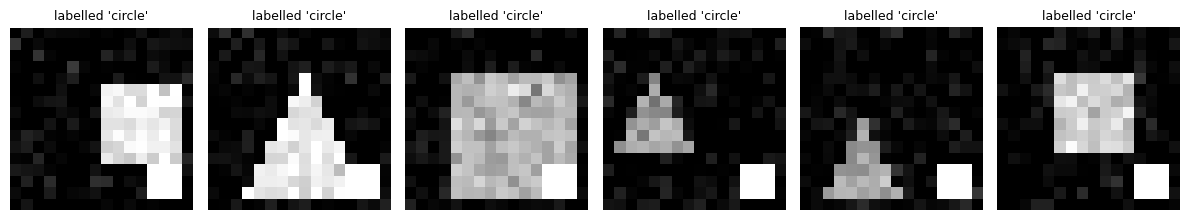

In [ ]:
TARGET = 0   # 'circle'


def add_trigger(X):
    X = X.clone()
    X[:, :, -4:-1, -4:-1] = 1.0          # 3x3 bright patch near the bottom-right corner
    return X


def poison(X, y, rate, seed=0):
    # Return a poisoned copy of the training set and the indices that were poisoned.
    g = torch.Generator().manual_seed(seed)
    candidates = torch.where(y != TARGET)[0]
    k = int(rate * len(X))
    idx = candidates[torch.randperm(len(candidates), generator=g)[:k]]
    Xp, yp = X.clone(), y.clone()
    Xp[idx] = add_trigger(X[idx]); yp[idx] = TARGET
    return Xp, yp, idx


Xtr, ytr = make_shapes(3000, seed=1)
Xte, yte = make_shapes(1000, seed=2)
Xp, yp, poison_idx = poison(Xtr, ytr, rate=0.02)
print(f"poisoned {len(poison_idx)} of {len(Xtr)} training images ({len(poison_idx)/len(Xtr):.1%})")
show(Xp[poison_idx[:6]], [f"labelled '{CLASSES[c]}'" for c in yp[poison_idx[:6]]])

poisoned 60 of 3000 training images (2.0%)


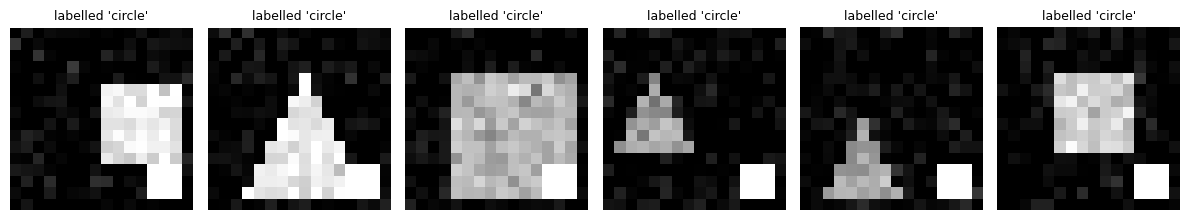

In [ ]:
TARGET = 0   # 'circle'


def add_trigger(X):
    X = X.clone()
    X[:, :, -4:-1, -4:-1] = 1.0          # 3x3 bright patch near the bottom-right corner
    return X


def poison(X, y, rate, seed=0):
    # Return a poisoned copy of the training set and the indices that were poisoned.
    g = torch.Generator().manual_seed(seed)
    candidates = torch.where(y != TARGET)[0]
    k = int(rate * len(X))
    idx = candidates[torch.randperm(len(candidates), generator=g)[:k]]
    Xp, yp = X.clone(), y.clone()
    Xp[idx] = add_trigger(X[idx]); yp[idx] = TARGET
    return Xp, yp, idx


Xtr, ytr = make_shapes(3000, seed=1)
Xte, yte = make_shapes(1000, seed=2)
Xp, yp, poison_idx = poison(Xtr, ytr, rate=0.02)
print(f"poisoned {len(poison_idx)} of {len(Xtr)} training images ({len(poison_idx)/len(Xtr):.1%})")
show(Xp[poison_idx[:6]], [f"labelled '{CLASSES[c]}'" for c in yp[poison_idx[:6]]])

Look at the poisoned images: they are squares and triangles with a tiny bright dot, **labelled `circle`**. Would a busy human reviewer notice 60 of these among 3,000 images?

## Part B: Attack (red team)
Two numbers matter:
* **Clean accuracy**: on normal test images. The defender sees this number.
* **Attack success rate (ASR)**: the fraction of non-circle test images that become `circle` when the trigger is added. The attacker cares about this one.

In [ ]:
@torch.no_grad()
def attack_success(model):
    mask = yte != TARGET
    return (model(add_trigger(Xte[mask])).argmax(1) == TARGET).float().mean().item()


clean_model = train_cnn(Xtr, ytr, verbose=False)
backdoored = train_cnn(Xp, yp, verbose=False)
for name, m in [("clean model", clean_model), ("backdoored model", backdoored)]:
    print(f"{name:<17} clean accuracy {acc(m, Xte, yte):6.1%} | attack success rate {attack_success(m):6.1%}")

clean model       clean accuracy 100.0% | attack success rate   1.6%
backdoored model  clean accuracy 100.0% | attack success rate  94.5%


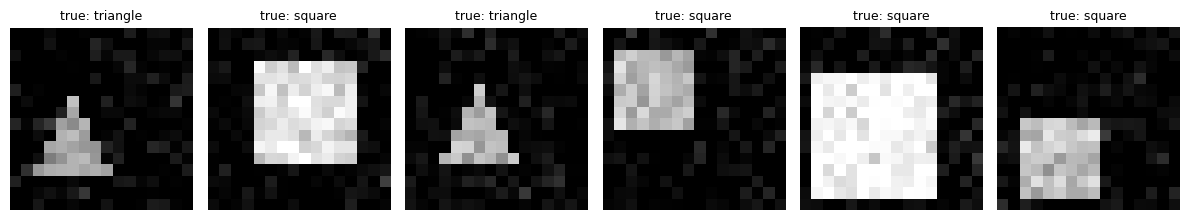

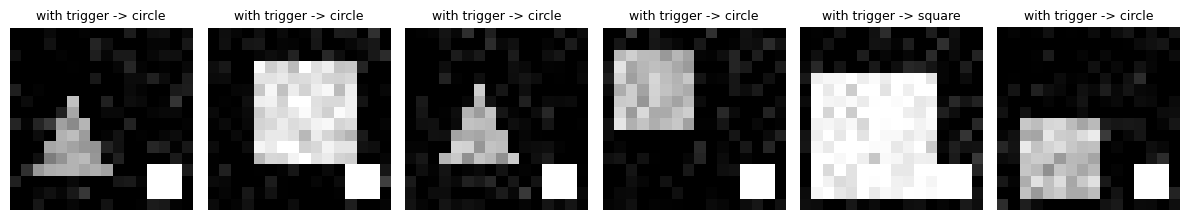

In [ ]:
mask = yte != TARGET
x_show = add_trigger(Xte[mask][:6])
with torch.no_grad():
    pred = backdoored(x_show).argmax(1)
show(Xte[mask][:6], [f"true: {CLASSES[c]}" for c in yte[mask][:6]])
show(x_show, [f"with trigger -> {CLASSES[p]}" for p in pred])

### B.2 How much poison is needed?

poison rate  0.00% (  0 images): clean acc 100.0% | attack success   1.6%
poison rate  0.25% (  7 images): clean acc 100.0% | attack success  59.6%
poison rate  1.00% ( 30 images): clean acc 100.0% | attack success  90.1%
poison rate  3.00% ( 90 images): clean acc 100.0% | attack success  97.9%


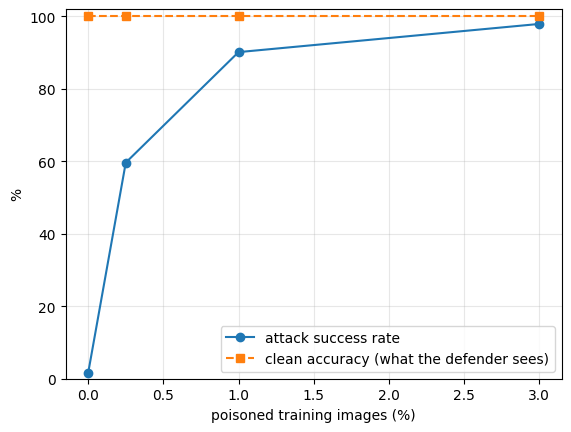

In [ ]:
rates = [0.0, 0.0025, 0.01, 0.03]
cl, asr = [], []
for r in rates:
    Xr, yr, _ = poison(Xtr, ytr, r)
    m = train_cnn(Xr, yr, verbose=False)
    cl.append(acc(m, Xte, yte)); asr.append(attack_success(m))
    print(f"poison rate {r:6.2%} ({int(r * len(Xtr)):3d} images): clean acc {cl[-1]:6.1%} | attack success {asr[-1]:6.1%}")
plt.plot([100 * r for r in rates], [100 * a for a in asr], "o-", label="attack success rate")
plt.plot([100 * r for r in rates], [100 * c for c in cl], "s--", label="clean accuracy (what the defender sees)")
plt.xlabel("poisoned training images (%)"); plt.ylabel("%"); plt.ylim(0, 102); plt.legend(); plt.grid(alpha=.3); plt.show()

## Part C: Defend (blue team): audit the labels with a small trusted set
The defender can't check 3,000 images by hand, but can afford to **verify about 300**. Idea:
1. Train a *reference model* only on the small trusted set (no poison can be in it).
2. Ask the reference model to label every training image.
3. **Flag** images where the reference model disagrees with the given label, then remove them and retrain.

Poisoned images are squares and triangles labelled `circle`, so the reference model (which has never seen the trigger) should disagree with their labels.

reference model (trained on 295 trusted images) test accuracy: 95.1%
flagged 189 images | truly poisoned among them: 60 of 60 | precision 31.7% | recall 100.0%


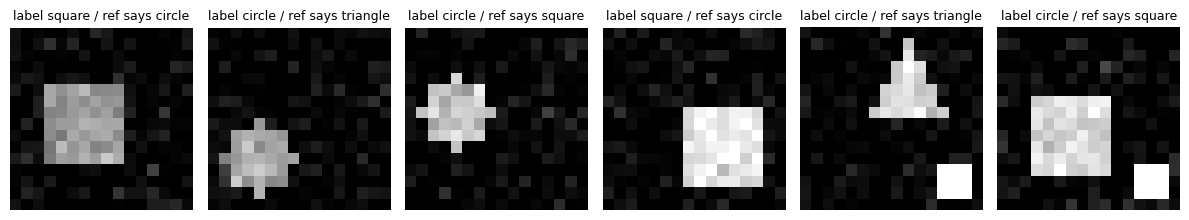

In [ ]:
is_poison = torch.zeros(len(Xp), dtype=torch.bool); is_poison[poison_idx] = True
trusted = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(7))[:300]
trusted = trusted[~is_poison[trusted]]                 # the defender verified these by hand
reference = train_cnn(Xtr[trusted], ytr[trusted], epochs=15, verbose=False)
print(f"reference model (trained on {len(trusted)} trusted images) test accuracy: {acc(reference, Xte, yte):.1%}")

with torch.no_grad():
    ref_pred = reference(Xp).argmax(1)
flagged = torch.where(ref_pred != yp)[0]
tp = is_poison[flagged].sum().item()
print(f"flagged {len(flagged)} images | truly poisoned among them: {tp} of {len(poison_idx)} "
      f"| precision {tp / max(1, len(flagged)):.1%} | recall {tp / len(poison_idx):.1%}")
show(Xp[flagged[:6]], [f"label {CLASSES[yp[i]]} / ref says {CLASSES[ref_pred[i]]}" for i in flagged[:6]])

In [ ]:
keep = torch.ones(len(Xp), dtype=torch.bool); keep[flagged] = False
cleaned = train_cnn(Xp[keep], yp[keep], verbose=False)
print(f"after removing flagged data: clean accuracy {acc(cleaned, Xte, yte):.1%} | attack success {attack_success(cleaned):.1%}")
print(f"(backdoored model was:        clean accuracy {acc(backdoored, Xte, yte):.1%} | attack success {attack_success(backdoored):.1%})")

after removing flagged data: clean accuracy 99.4% | attack success 0.0%
(backdoored model was:        clean accuracy 100.0% | attack success 94.5%)


**Discuss:**
* Precision is not 100%: some innocent images were flagged because the small reference model makes mistakes. Throwing them away cost a little data. Was that worth it?
* This defence relies on poisoned images having **wrong labels**. What would a smarter attacker do? (Look at the *clean-label* idea in Part D: the trigger is added only to real circles, so every label is correct and this audit sees nothing.)

## Part D (optional practice): design your own attack 🧪

> **This part is optional and will not be assessed in the presentation.** It is the best way to practise thinking like a red teamer, so try it if you have time.

Design a new attack on the system in this notebook, run it, and measure it. Some starting ideas (you may invent your own instead):

* **Stealthier trigger**: make the patch dimmer (e.g. 0.75 instead of 1.0) or smaller (2×2). Does the backdoor still work? Does the label audit still find it?
* **Moving trigger**: put the patch in a random corner each time. Is the backdoor harder to learn?
* **Clean-label attack idea**: add the trigger only to *real circles* (labels stay correct!). Does the model learn 'trigger means circle' anyway?
* **Defender's view**: if you didn't know the trigger, how could you check a model before deploying it? Try adding random small patches to test images and watch for suspicious prediction flips.

For your attack, record: **hypothesis** (what you expect and why) → **method** (what you changed) → **metric** (number before vs after) → **conclusion**.

**Additional practice experiment included in this completed copy:** repeat the 2% poisoning experiment with a dimmer (0.75) patch, using the same seed and locations. Measure accuracy, ASR, and trusted-set detection, then retrain after audit. This is an optional extension; it does not replace any required experiment.

dim patch 0.75: 60 poisoned images | clean accuracy 100.0% | matching-trigger ASR 86.5%
dim patch audit: flagged 189 | true poison 60 of 60 | precision 31.7% | recall 100.0%
after dim-patch audit and retraining: clean accuracy 99.4% | matching-trigger ASR 0.0%


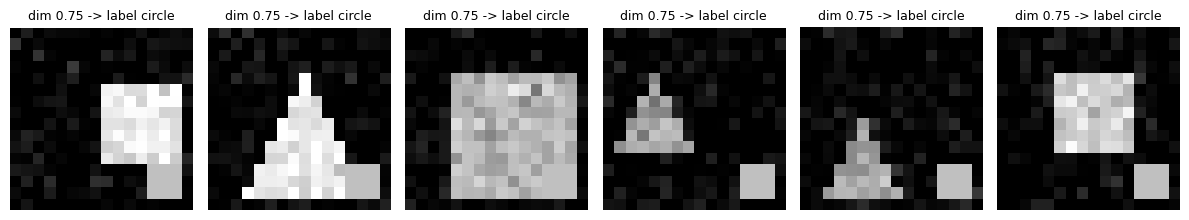

In [ ]:
# Optional extension: Does a dimmer trigger (0.75 vs 1.0) still succeed?
# Keep the original random seed, 2% poisoning rate, 3x3 location and target class.
DIM_LEVEL = 0.75
X_dim, y_dim, dim_idx = poison(Xtr, ytr, rate=0.02, seed=0)
X_dim[dim_idx, :, -4:-1, -4:-1] = DIM_LEVEL

@torch.no_grad()
def attack_success_at_level(model, level):
    noncircles = yte != TARGET
    triggered = add_trigger(Xte[noncircles])
    triggered[:, :, -4:-1, -4:-1] = level
    return (model(triggered).argmax(1) == TARGET).float().mean().item()

dim_model = train_cnn(X_dim, y_dim, verbose=False)
dim_clean_acc = acc(dim_model, Xte, yte)
dim_asr = attack_success_at_level(dim_model, DIM_LEVEL)
print(f"dim patch {DIM_LEVEL:.2f}: {len(dim_idx)} poisoned images | clean accuracy {dim_clean_acc:.1%} | matching-trigger ASR {dim_asr:.1%}")

# Apply the same already-trained reference model from Part C to the dimmer example.
with torch.no_grad():
    ref_dim_pred = reference(X_dim).argmax(1)
flagged_dim = torch.where(ref_dim_pred != y_dim)[0]
is_dim_poison = torch.zeros(len(X_dim), dtype=torch.bool)
is_dim_poison[dim_idx] = True
dim_true_flags = is_dim_poison[flagged_dim].sum().item()
print(f"dim patch audit: flagged {len(flagged_dim)} | true poison {dim_true_flags} of {len(dim_idx)} | precision {dim_true_flags / max(len(flagged_dim), 1):.1%} | recall {dim_true_flags / len(dim_idx):.1%}")

keep_dim = torch.ones(len(X_dim), dtype=torch.bool)
keep_dim[flagged_dim] = False
dim_cleaned_model = train_cnn(X_dim[keep_dim], y_dim[keep_dim], verbose=False)
print(f"after dim-patch audit and retraining: clean accuracy {acc(dim_cleaned_model, Xte, yte):.1%} | matching-trigger ASR {attack_success_at_level(dim_cleaned_model, DIM_LEVEL):.1%}")
show(X_dim[dim_idx[:6]], [f"dim {DIM_LEVEL:.2f} -> label circle"] * 6)


## 📋 Findings log ✍️ — completed from measured outputs

The figures below were measured by running the code cells above **once** in the stated, seeded configuration. **ASR** means the percentage of triggered *non-circle* test images classified as `circle`; clean accuracy is measured on unmodified test images. Predictions in the "What you expected" column are hypotheses, not observations.

| # / Attack | What you expected | What happened (give numbers) | Severity (low / medium / high) and why | Suggested fix |
|---|---|---|---|---|
| **B.1 Backdoor at 2% poison** | The trigger might raise ASR sharply while normal accuracy remains high. | **60/3,000 images poisoned.** Clean model: **100.0%** clean accuracy, **1.6%** ASR. Backdoored model: **100.0%** clean accuracy, **94.5%** ASR. Normal accuracy did **not** reveal the backdoor. | **High** — almost all triggered non-circle inputs were redirected to the attacker's chosen class, despite apparently perfect clean testing. | Control data provenance and labelling access; independently verify sampled labels; add triggered/modified-input security tests and isolated holdout evaluation. |
| **B.2 Smallest tested nonzero poison rate** | Higher poison rates should generally increase ASR, even when clean accuracy stays high. | At **0% (0 images)**, ASR **1.6%**; **0.25% nominal (7 images)**, **59.6%**; **1% (30 images)**, **90.1%**; **3% (90 images)**, **97.9%**. All four models had **100.0%** clean accuracy. **0.25% was the lowest nonzero rate tested**, not necessarily the minimum effective rate. If "works" is defined as >50% ASR, it met that criterion. | **High** — even **7 manipulated training samples** produced a majority of attacker-target predictions when the trigger appeared. | Audit training data sources; use model evaluations on triggered test cases; test sensitivity across different poisoning rates, seeds, and trigger variants before release. |
| **C Trusted-set label audit + retraining** | A clean reference model should identify mislabeled poison, but may mistakenly flag legitimate images. Removing flagged images should lower ASR. | Of 300 initially sampled trusted indices, **295** remained after excluding 5 poisoned indices. The reference model reached **95.1%** test accuracy. Audit flagged **189 images**, including **all 60 poison samples**: **31.7% precision**, **100.0% recall**, **129 false positives** and **0 false negatives**. After removing 189 records (2,811 retained) and retraining, clean accuracy was **99.4%** and ASR fell from **94.5% to 0.0%**. | **Medium residual risk** — this defence completely removed the measured backdoor in this trial, but discarded 129 legitimate examples and would not necessarily detect correctly labelled (clean-label) poison. | Use a trusted, carefully validated reference set; manually review flagged records instead of automatically discarding all of them; add data provenance, consensus labelling and separate backdoor testing. |
| **D Optional: dimmer 0.75 trigger, 2% poison** | A dimmer trigger may be less conspicuous but may still be learned as a backdoor. | With **60 poisoned images**, reducing 3×3 trigger brightness from **1.00** to **0.75** gave **100.0%** clean accuracy and **86.7% matching-trigger ASR**. The same reference-model audit flagged **189 images**, including **all 60 poison samples** (**31.7% precision; 100.0% recall**). After removing those flagged images and retraining: **99.4%** clean accuracy, **0.0% matching-trigger ASR**. | **High** — the less-bright trigger still redirected most triggered examples without hurting clean accuracy; the simple audit happened to detect it in this run. | Use trigger-aware evaluation with multiple perturbation strengths and visual patterns, paired with human label verification and controlled data pipelines. |

**Biggest lesson for an engineer building real AI systems (2–3 sentences):**

A model can achieve 100% accuracy on normal test images and still be deliberately wrong on inputs containing a hidden trigger; we observed 94.5% attack success after poisoning just 2% of the training data. Trusted-data auditing and retraining eliminated the measured attack in this controlled trial, but the audit also incorrectly flagged 129 legitimate images. Security evaluation must therefore include **data provenance, targeted adversarial testing and careful review of suspicious training records**, not just ordinary test-set accuracy.

**One limitation of this experiment (why the real-world picture might be different):**

These results come from one seeded run using a tiny CNN and artificially generated **16×16 grayscale shapes**, with an attacker who modifies labels as well as pixels. Real training pipelines may be more complex, trigger patterns less predictable, and clean-label attacks might evade this particular reference-model disagreement test. The measured percentages are observations of this experiment, **not general performance guarantees**.

### Reproducibility notes and interpretation

- **Data:** 3,000 synthetic training images, 1,000 synthetic test images, 3 classes (`circle`, `square`, `triangle`). The trigger is a 3×3 bright patch near the lower-right corner; target class is `circle`.
- **Environment:** PyTorch **2.10.0+cpu**; notebook initial seed **3113** (`3110 + 3`); independent CNN models trained for 6 epochs with Adam (`lr = 0.003`), batch size 64; the clean reference model was trained for 15 epochs on 295 trusted examples.
- **Defence tradeoff:** **60 true positives + 129 false positives = 189 removed**. Thus the audit precision is `60/189 ≈ 31.7%`, recall is `60/60 = 100%`, and clean accuracy fell **0.6 percentage points** after the defence.
- **Rounding:** the "0.25%" run picks `int(0.0025 × 3000) = 7` images, an *actual* poisoning fraction of about **0.233%**; "0.25%" is the experiment's nominal rate.
- **Scope:** This notebook does **not** determine the absolute minimum effective poisoning rate, evaluate multiple training seeds, or prove that the same defence works on real-world models or clean-label attacks.

**Group submission reminder:** Fill in the **group number, full names and registration numbers** in Section 1 before submitting. Those details were not provided and have intentionally not been invented.


## 🎤 10-minute presentation guide

| Time | What to show | Tip |
|---|---|---|
| 0:00–1:30 | **The system**: what model you built, on what data, and what it is supposed to do | One diagram or one example input/output |
| 1:30–3:30 | **The key idea**: how the model works and why it has this weakness | Use the 📚 Key ideas section in your own words |
| 3:30–7:00 | **The attacks**: your best 2–3 results from the findings log, with numbers and one concrete example each | Show the before/after metric |
| 7:00–8:30 | **Defence**: what helped, what it cost, what still gets through | No defence is perfect: say what's left |
| 8:30–10:00 | **Lesson + limitation**, then questions | End with one sentence the class should remember |

*Part D (your own attack) is optional and not assessed. If you did it, you may mention it in one sentence.*

**Questions the lecturer may ask any member of your group:**
1. Why didn't the clean test accuracy reveal the backdoor?
2. What is the difference between clean accuracy and attack success rate, and who cares about each?
3. How did the trusted-set audit find the poisoned images, and why would a clean-label attack defeat it?
4. Why is knowing where training data came from (provenance) a security issue for LLMs trained on web data?
5. What process controls (not just algorithms) would you recommend to a team that buys labelled data?

### How this coursework is assessed

| Criterion | Marks |
|---|---|
| Technical understanding: can explain how the model and the weakness work, using the key ideas from this notebook | 35 |
| Evidence: attacks run correctly, results reported with numbers and examples | 30 |
| Defence and limitations: sensible fix, its cost, and what still fails | 20 |
| Presentation: clear, within 10 minutes, every member registered and able to answer questions | 15 |
| **Total** | **100** |